In [29]:
import os

os.environ["KERAS_BACKEND"] = "torch"

# 1. Business Understanding


In [30]:
import csv
import time
import keras
from keras import layers
from keras.regularizers import l2

import numpy as np
import matplotlib.pyplot as plt

TARGET_REALISTIC = (0.70, 0.75)
TARGET_AMBITIOUS = (0.78, 0.80)

### random seed for repeatability
RANDOM_SEED = 123
keras.utils.set_random_seed(RANDOM_SEED)

# 2. Data Understanding

In [31]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()
y_train, y_test = y_train.flatten(), y_test.flatten()

class_names = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

print("Train: ", x_train.shape, "Test: ", x_test.shape)
print("Pixel range: ", x_train.min(), "-", x_train.max())

Train:  (50000, 32, 32, 3) Test:  (10000, 32, 32, 3)
Pixel range:  0 - 255


### Sample Images

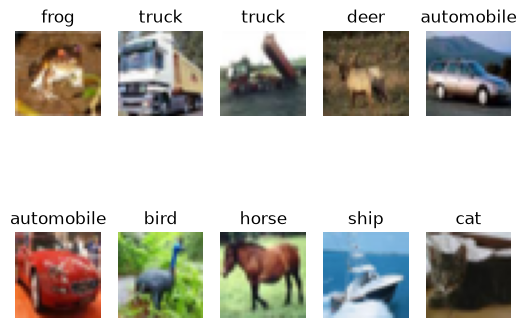

In [32]:
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].reshape(32, 32, 3))
    plt.title(class_names[y_train[i]])
    plt.axis("off")
plt.show()

# 3. Data Preparation

In [33]:
x_train = x_train.astype("float32")
x_test = x_test.astype("float32")

x_train = x_train.astype("float32") / 255
x_test = x_test.astype("float32") / 255

# 4. Modeling

In [34]:
# one residual block: two conv layers plus a shortcut that skips over them
def residual_block(x, filters, strides=1):
    shortcut = x
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    # the shortcut must have the same shape as the block output
    if strides != 1 or shortcut.shape[-1] != filters:
        shortcut = layers.Conv2D(filters, 1, strides=strides, use_bias=False)(x)

    x = layers.Conv2D(filters, 3, strides=strides, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)

    # add the shortcut back to the output
    return layers.Add()([shortcut, x])

inputs = keras.Input(shape=(32, 32, 3))

# data augmentation: random flips and small shifts
x = layers.RandomFlip("horizontal")(inputs)
x = layers.RandomTranslation(0.125, 0.125)(x)

# first conv layer
x = layers.Conv2D(32, 3, padding="same", use_bias=False)(x)

# three stages with 2 residual blocks each, strides=2 makes the image smaller
x = residual_block(x, 32)
x = residual_block(x, 32)
x = residual_block(x, 64, strides=2)
x = residual_block(x, 64)
x = residual_block(x, 128, strides=2)
x = residual_block(x, 128)

# classifier
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(10, activation="softmax")(x)
model = keras.Model(inputs=inputs, outputs=outputs)

In [35]:
model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_flip_1       │ (None, 32, 32, 3) │          0 │ input_layer_2[0]… │
│ (RandomFlip)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_translation… │ (None, 32, 32, 3) │          0 │ random_flip_1[0]… │
│ (RandomTranslation) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 32, 32,    │        864 │ random_translati… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_6[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 32, 32,    │      9,216 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_7[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 32, 32,    │      9,216 │ activation_1[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 32, 32,    │          0 │ conv2d_6[0][0],   │
│                     │ 32)               │            │ conv2d_8[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ add[0][0]         │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 32, 32,    │      9,216 │ activation_2[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_9[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 32, 32,    │      9,216 │ activation_3[0][

 Total params: 698,090 (2.66 MB)

 Trainable params: 696,234 (2.66 MB)

 Non-trainable params: 1,856 (7.25 KB)

In [36]:
run_name = "run5_resnet"
epochs = 30
batch_size = 128
time_limit = 30 * 60  # seconds

# the learning rate gets smaller during training
steps_per_epoch = int(np.ceil(len(x_train) * 0.8 / batch_size))
learning_rate = keras.optimizers.schedules.CosineDecay(1e-3, decay_steps=epochs * steps_per_epoch)

# adamw is adam with weight decay, which keeps the weights small
model.compile(
    loss=keras.losses.SparseCategoricalCrossentropy(),
    optimizer=keras.optimizers.AdamW(learning_rate=learning_rate, weight_decay=5e-3),
    metrics=["accuracy"],
)

In [37]:
# stop before the next epoch would go over the time limit
def stop_if_out_of_time(epoch, logs):
    elapsed = time.time() - t0
    if elapsed + elapsed / (epoch + 1) > time_limit:
        model.stop_training = True

callbacks = [
    # stop if validation accuracy has not improved for 10 epochs, then go back to the best epoch
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=10, restore_best_weights=True, verbose=1),
    # save the best model to a file during training
    keras.callbacks.ModelCheckpoint(f"cnn_history/{run_name}_best.keras", monitor="val_accuracy", save_best_only=True),
    keras.callbacks.LambdaCallback(on_epoch_end=stop_if_out_of_time),
]

t0 = time.time()
history = model.fit(
    x_train, y_train,
    batch_size=batch_size,
    epochs=epochs,
    validation_split=0.2,
    callbacks=callbacks,
)
training_time = time.time() - t0
print("Training time: ", round(training_time, 1), " seconds")

Epoch 1/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 56s 177ms/step - accuracy: 0.4499 - loss: 1.4921 - val_accuracy: 0.2773 - val_loss: 2.5294
Epoch 2/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 56s 179ms/step - accuracy: 0.6067 - loss: 1.1026 - val_accuracy: 0.3650 - val_loss: 2.6059
Epoch 3/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 55s 177ms/step - accuracy: 0.6765 - loss: 0.9235 - val_accuracy: 0.5532 - val_loss: 1.3495
Epoch 4/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 55s 175ms/step - accuracy: 0.7207 - loss: 0.8038 - val_accuracy: 0.6390 - val_loss: 1.0869
Epoch 5/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 55s 177ms/step - accuracy: 0.7547 - loss: 0.7113 - val_accuracy: 0.6559 - val_loss: 1.0618
Epoch 6/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 55s 176ms/step - accuracy: 0.7782 - loss: 0.6442 - val_accuracy: 0.7226 - val_loss: 0.8090
Epoch 7/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 56s 178ms/step - accuracy: 0.7985 - loss: 0.5891 - val_accuracy: 0.6755 - val_loss: 1.1395
Epoch 8/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 55s 176ms/step - accuracy: 0.8120 - loss: 0

# 5. Evaluation

## Learning curves

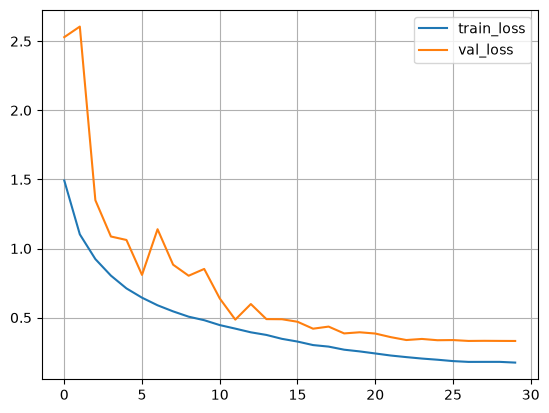

In [38]:
plt.plot(history.history["loss"], label="train_loss")
plt.plot(history.history["val_loss"], label="val_loss")
plt.legend()
plt.grid()
plt.show()

## Test accuracy

In [39]:
test_scores = model.evaluate(x_test, y_test, verbose=2)

print("Test loss: ", test_scores[0])
print("Test accuracy: ", test_scores[1])

313/313 - 4s - 11ms/step - accuracy: 0.8866 - loss: 0.3501
Test loss:  0.35005733370780945
Test accuracy:  0.8866000175476074


In [40]:
h = history.history
epochs_run = len(h["loss"])
best_epoch = int(np.argmax(h["val_accuracy"]))

# save the results of every epoch to a csv file
with open(f"cnn_history/{run_name}.csv", "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["epoch", "accuracy", "loss", "val_accuracy", "val_loss"])
    for i in range(epochs_run):
        writer.writerow([i + 1, round(h["accuracy"][i], 4), round(h["loss"][i], 4), round(h["val_accuracy"][i], 4), round(h["val_loss"][i], 4)])

# add a short summary of this run to the history file
with open("cnn_history/runs.txt", "a") as f:
    f.write(f"{run_name}\n")
    f.write(f"test accuracy: {test_scores[1]:.4f}, test loss: {test_scores[0]:.4f}\n")
    f.write(f"training time: {training_time:.1f} s, epochs run: {epochs_run}\n")
    f.write(f"best val accuracy: {h['val_accuracy'][best_epoch]:.4f} (epoch {best_epoch + 1})\n\n")

print("Train acc: ", round(h["accuracy"][best_epoch], 4), " Val acc: ", round(h["val_accuracy"][best_epoch], 4), " (best epoch", best_epoch + 1, "of", epochs_run, ")")

Train acc:  0.9416  Val acc:  0.8927  (best epoch 30 of 30 )


## Results grid

| Run | Regularization | Reg. settings | Conv filters | Augmentation | Optimizer | Batch size | Epochs | Train acc. | Val acc. | Test acc. | Time (s) |
|---|---|---|---|---|---|---|---|---|---|---|---|
| 1 | Dropout, BatchNorm | dropout 0.3 before output, BatchNorm after each conv | 64, 128, 256 | flip, translation 0.1 | Adam | 64 | 30 | 0.8460 | 0.8035 | **0.8013** | 479.3 |
| 2 | Dropout, BatchNorm, L2 | dropout 0.3 before output, BatchNorm after each conv, L2 1e-4 on conv + output | 64, 128, 256 | flip, translation 0.1 | Adam | 64 | 30 | 0.8182 | 0.8009 | **0.8003** | 1008.7 |
| 3 | None (barebones) | none | 64, 128, 256 | none | Adam | 64 | 30 | 0.9080 | 0.7734 | **0.7686** | 248.0 |
| 4 | BatchNorm only | BatchNorm after each conv | 64, 128, 256 | none | Adam | 64 | 30 | 0.9884 | 0.7462 | **0.7402** | 493.2 |
| 5 | Dropout, BatchNorm, weight decay, early stopping | ResNet, dropout 0.3 before output, AdamW weight decay 5e-3, cosine LR, patience 10, 30 min limit | 32, 64, 128 (2 residual blocks each) | flip, translation 0.125 | AdamW | 128 | 30 | 0.9416 | 0.8927 | **0.8866** | 1655.1 |


## Comparison of all runs

The top row shows the train and validation loss of each run, and the bottom row shows the accuracy. When the train and validation lines move apart, the model is overfitting: it keeps improving on the training images but not on new ones.

### How regularization helped

Run 3 (barebones) has no regularization. Train accuracy keeps rising, but validation accuracy stops improving, leaving a gap of 13.5 percentage points.

Run 4 (BatchNorm only) learns faster, but it overfits more, with a gap of 24.2 points. BatchNorm alone did not solve overfitting here.

Run 1 (dropout, BatchNorm, augmentation) shrinks the gap to 4.3 points and raises test accuracy from 76.9% to 80.1%. Dropout and augmentation make it harder for the model to memorize the training images.

Run 2 (Run 1 + L2) shrinks the gap further to 1.7 points, but test accuracy does not improve and training takes about twice as long. Its loss values also include the L2 penalty, so they are not directly comparable with the other runs.

### How more layers helped

Runs 1 to 4 have 3 convolutional layers. Run 5 has 13 main convolutional layers, with residual connections that help a deeper network train well. A deeper network can learn more complex shapes, and Run 5 reaches the best test accuracy, 88.7%, with a gap of 4.9 points. Run 5 also uses weight decay, stronger augmentation and a decreasing learning rate, so the improvement does not come from the extra layers alone.

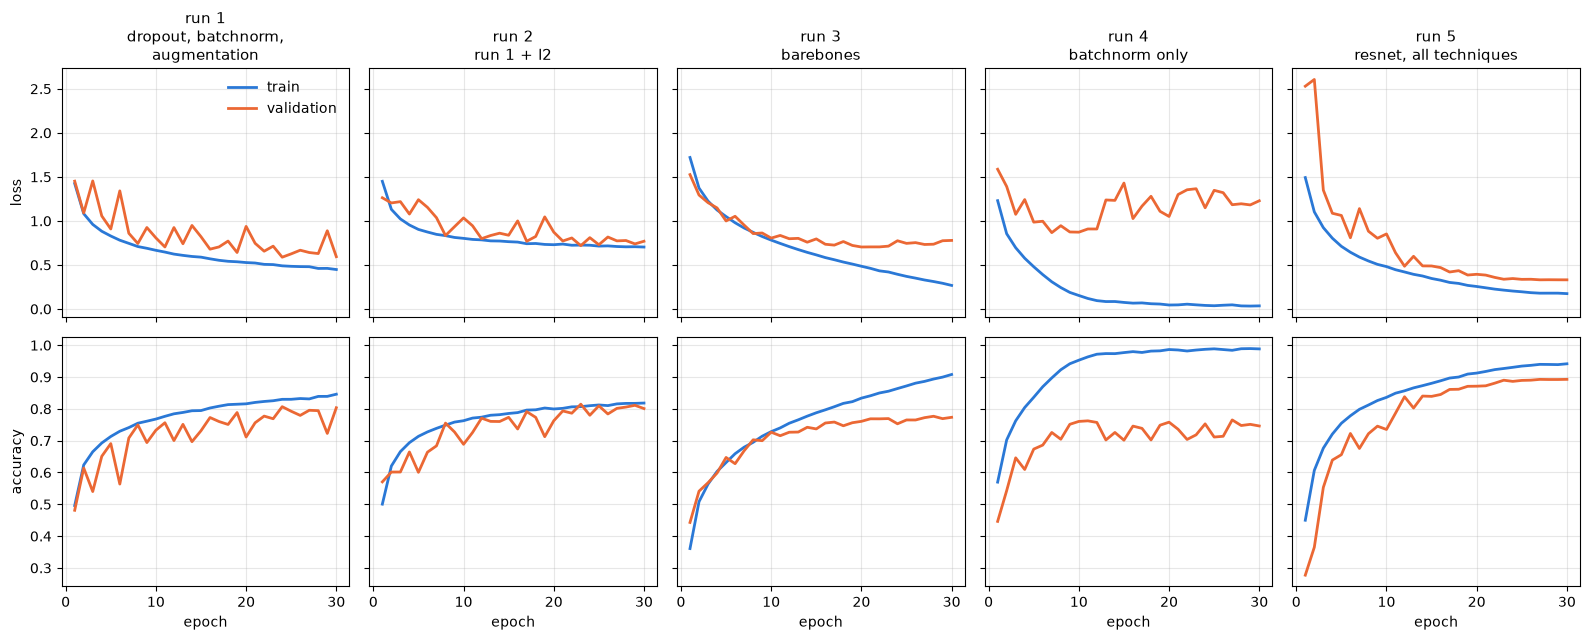

In [ ]:
# chart title and csv file of each run
runs = [
    ("run 1\ndropout, batchnorm,\naugmentation", "run1_dropout_batchnorm_aug"),
    ("run 2\nrun 1 + l2", "run2_dropout_batchnorm_aug_l2"),
    ("run 3\nbarebones", "run3_barebones"),
    ("run 4\nbatchnorm only", "run4_batchnorm_only"),
    ("run 5\nresnet, all techniques", "run5_resnet"),
]

# one column per run, loss on top and accuracy below
fig, axes = plt.subplots(2, 5, figsize=(16, 6.5), sharex=True, sharey="row")

for col, (title, name) in enumerate(runs):
    run = np.genfromtxt(f"cnn_history/{name}.csv", delimiter=",", names=True)

    # loss
    axes[0, col].plot(run["epoch"], run["loss"], color="#2a78d6", linewidth=2, label="train")
    axes[0, col].plot(run["epoch"], run["val_loss"], color="#eb6834", linewidth=2, label="validation")
    axes[0, col].set_title(title, fontsize=11)
    axes[0, col].grid(alpha=0.3)

    # accuracy
    axes[1, col].plot(run["epoch"], run["accuracy"], color="#2a78d6", linewidth=2, label="train")
    axes[1, col].plot(run["epoch"], run["val_accuracy"], color="#eb6834", linewidth=2, label="validation")
    axes[1, col].set_xlabel("epoch")
    axes[1, col].grid(alpha=0.3)

axes[0, 0].set_ylabel("loss")
axes[1, 0].set_ylabel("accuracy")
axes[0, 0].legend(frameon=False)

plt.tight_layout()
plt.savefig("cnn_history/all_runs_comparison.png", dpi=150)
plt.show()

## Probability distributions

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step


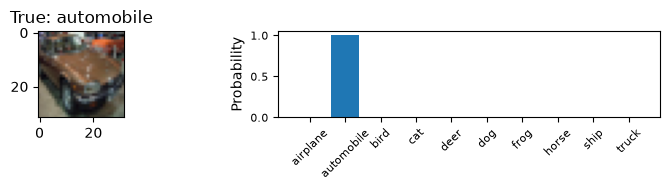

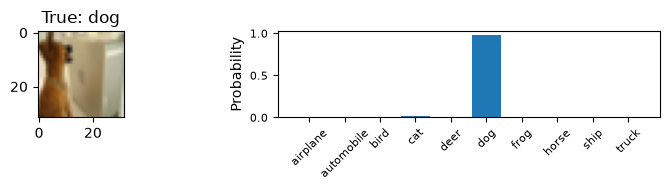

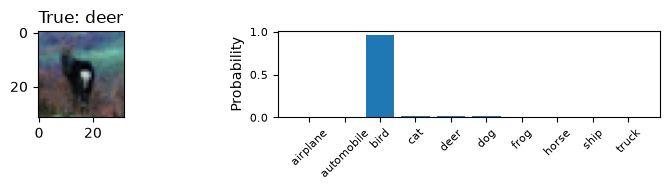

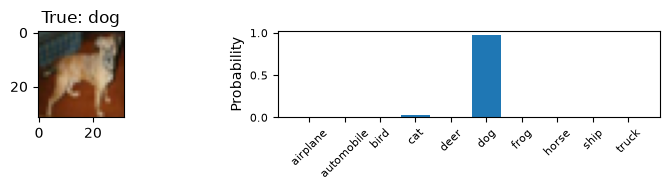

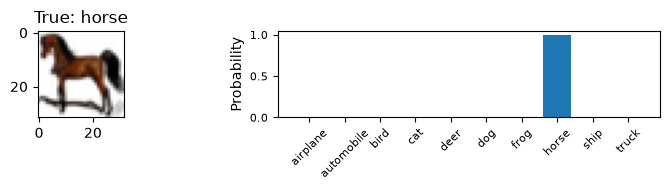

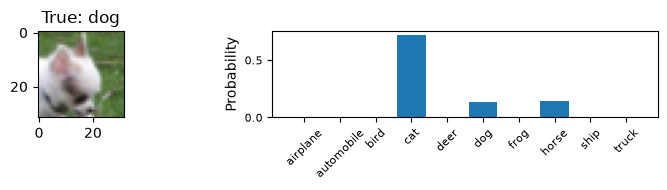

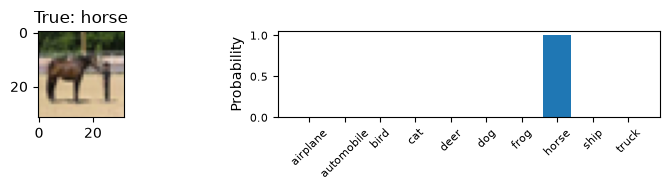

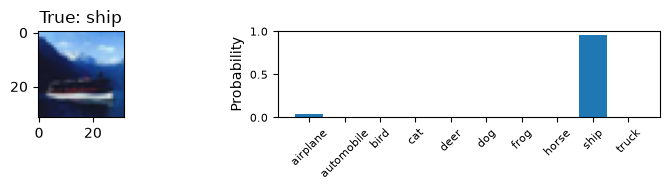

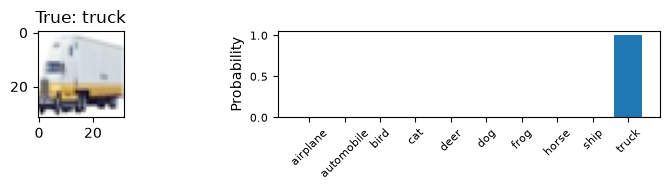

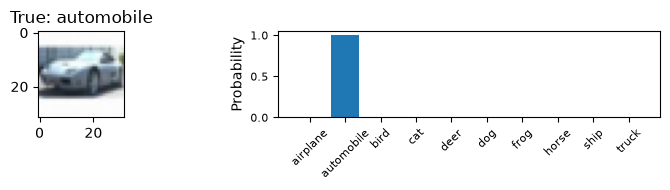

In [42]:
def to_img(x):
    img = x * 255
    return np.clip(img / 255, 0, 1)

y = model.predict(x_test)
start = 2000

for k in range(10):
    plt.figure(figsize=(8, 2))
    plt.subplot(1, 2, 1)
    plt.imshow(to_img(x_test[start + k]))
    plt.title("True: " + class_names[y_test[start+k]], fontsize=12)
    plt.subplot(1, 2, 2)
    plt.bar(np.arange(10), y[start+k])
    plt.xticks(range(10), class_names, rotation=45, fontsize=8)
    plt.yticks(fontsize=8)
    plt.ylabel("Probability", fontsize=10)
    plt.tight_layout()

## Misclassified images

Misclassified:  1134 / 10000


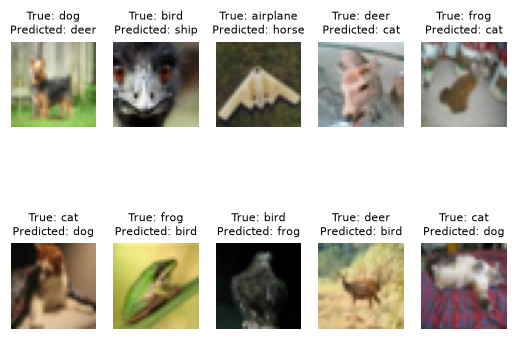

In [43]:
y_pred = np.argmax(y, axis=1)
wrong = np.where(y_pred != y_test)[0]

print("Misclassified: ", len(wrong), "/", len(y_test))

for k in range(10):
    i = wrong[k]
    plt.subplot(2, 5, k+1)
    plt.imshow(to_img(x_test[i]))
    plt.title(f"True: {class_names[y_test[i]]}\nPredicted: {class_names[y_pred[i]]}", fontsize=8)
    plt.axis("off")
plt.show()

## Comparison with FCN

In [44]:
FCN_TEST_ACCURACY = 0.4806
FCN_TRAINING_TIME = 79.3

print("FCN test accuracy: ", FCN_TEST_ACCURACY, " training time: ", FCN_TRAINING_TIME, " seconds")
print("CNN test accuracy: ", round(test_scores[1], 4), " training time: ", round(training_time, 1), " seconds")

FCN test accuracy:  0.4806  training time:  79.3  seconds
CNN test accuracy:  0.8866  training time:  1655.1  seconds
